In [110]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [111]:
raw_df = pd.read_csv('student-mat.csv', sep=';')
pd.set_option('display.max_columns', None)

EDA - Exploratory Data Analysis

In [112]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [113]:
for cols in raw_df.columns:
    print(cols, " : ", raw_df[cols].nunique()," : ", raw_df[cols].unique(), " : ",raw_df.value_counts(cols))

school  :  2  :  ['GP' 'MS']  :  school
GP    349
MS     46
Name: count, dtype: int64
sex  :  2  :  ['F' 'M']  :  sex
F    208
M    187
Name: count, dtype: int64
age  :  8  :  [18 17 15 16 19 22 20 21]  :  age
16    104
17     98
15     82
18     82
19     24
20      3
21      1
22      1
Name: count, dtype: int64
address  :  2  :  ['U' 'R']  :  address
U    307
R     88
Name: count, dtype: int64
famsize  :  2  :  ['GT3' 'LE3']  :  famsize
GT3    281
LE3    114
Name: count, dtype: int64
Pstatus  :  2  :  ['A' 'T']  :  Pstatus
T    354
A     41
Name: count, dtype: int64
Medu  :  5  :  [4 1 3 2 0]  :  Medu
4    131
2    103
3     99
1     59
0      3
Name: count, dtype: int64
Fedu  :  5  :  [4 1 2 3 0]  :  Fedu
2    115
3    100
4     96
1     82
0      2
Name: count, dtype: int64
Mjob  :  5  :  ['at_home' 'health' 'other' 'services' 'teacher']  :  Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64
Fjob  :  5  :  ['teacher' 'oth

In [114]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [115]:
fig = px.histogram(raw_df, x='G3',title='Marks vs Count',nbins=21)
fig.update_layout(bargap=0.1)
fig.show()

In [116]:
(raw_df['G3']>=10).astype(int)

0      0
1      0
2      1
3      1
4      1
      ..
390    0
391    1
392    0
393    1
394    0
Name: G3, Length: 395, dtype: int64

In [117]:
raw_df['pass'] = (raw_df['G3']>=10).astype(int)

In [118]:
raw_df.corr(numeric_only=True)['pass'].sort_values(ascending = False)

pass          1.000000
G3            0.770042
G2            0.725407
G1            0.664979
Medu          0.115396
Fedu          0.108057
studytime     0.074613
famrel        0.046683
freetime     -0.018321
Walc         -0.029957
traveltime   -0.044446
Dalc         -0.057343
health       -0.065668
absences     -0.092244
age          -0.179645
goout        -0.183399
failures     -0.337731
Name: pass, dtype: float64

<Axes: >

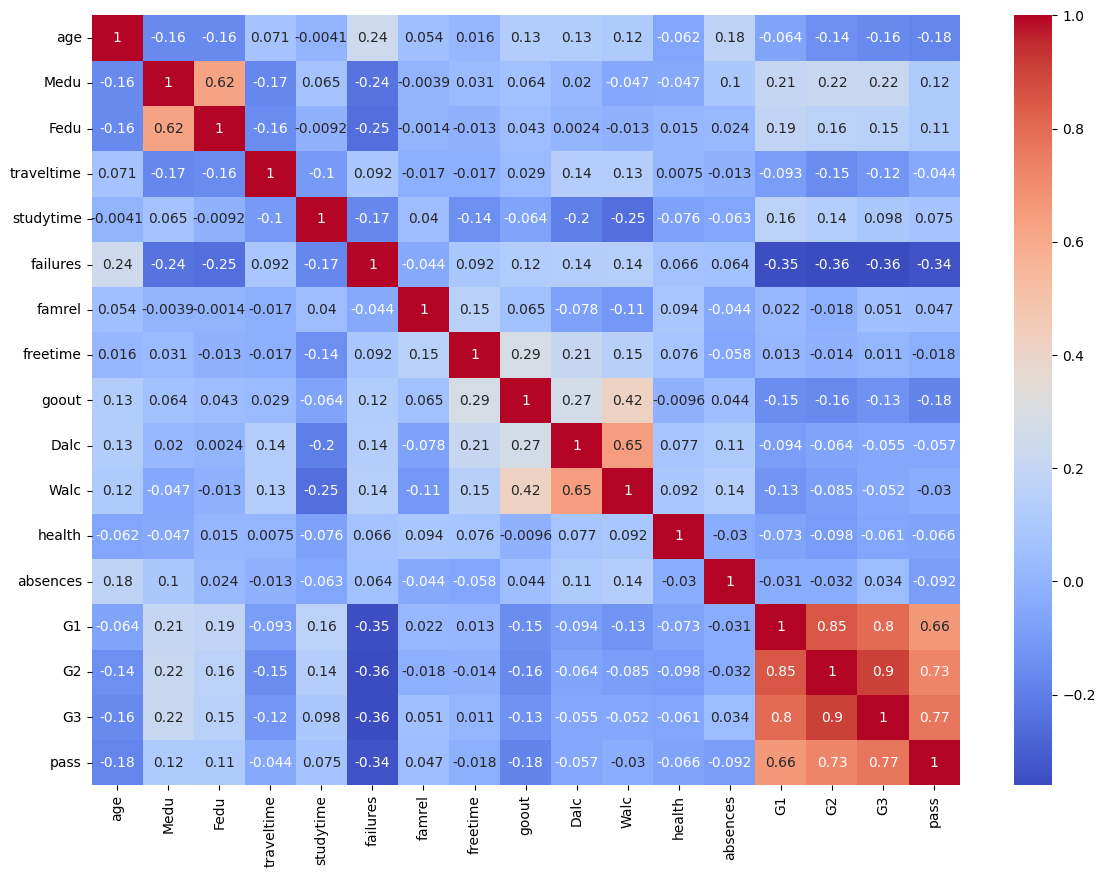

In [119]:
plt.figure(figsize=(14, 10))
sns.heatmap(raw_df.corr(numeric_only=True),annot=True,cmap='coolwarm',)

In [120]:
X = raw_df.drop(columns=['pass','G3'])
y = raw_df['pass']

In [121]:
from sklearn.model_selection import train_test_split

In [122]:
X_train, X_val_test , y_train , y_val_test = train_test_split(X,y,test_size=0.4,random_state=42,stratify=y)
X_val, X_test , y_val, y_test = train_test_split(X_val_test,y_val_test,test_size=0.5,random_state=42,stratify=y_val_test)

In [123]:
X_train.shape, X_val.shape, X_test.shape

((237, 32), (79, 32), (79, 32))

In [124]:
object_cols = X_train.select_dtypes(include='object').columns.tolist()

In [125]:
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()

In [126]:
from sklearn.preprocessing import MinMaxScaler

In [127]:
scaler = MinMaxScaler()

In [128]:
scaler.fit(X_train[numeric_cols])

MinMaxScaler()

In [129]:
X_train[numeric_cols] = scaler.transform(X_train[numeric_cols])
X_val[numeric_cols] = scaler.transform(X_val[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [130]:
X_train.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
count,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000,237.000000
mean,0.229054,0.678270,0.621308,0.153305,0.348805,0.112518,0.728903,0.562236,0.522152,0.116034,0.317511,0.655063,0.073474,0.464979,0.567177
std,0.187078,0.283034,0.280548,0.232554,0.274882,0.255814,0.230323,0.255404,0.281463,0.220112,0.326576,0.354235,0.110384,0.216714,0.200273
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.142857,0.500000,0.500000,0.000000,0.000000,0.000000,0.500000,0.500000,0.250000,0.000000,0.000000,0.500000,0.000000,0.266667,0.473684
50%,0.142857,0.750000,0.500000,0.000000,0.333333,0.000000,0.750000,0.500000,0.500000,0.000000,0.250000,0.750000,0.026667,0.466667,0.578947
75%,0.428571,1.000000,1.000000,0.333333,0.333333,0.000000,1.000000,0.750000,0.750000,0.250000,0.500000,1.000000,0.106667,0.600000,0.684211
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [131]:
from sklearn.preprocessing import OneHotEncoder

In [132]:
encoder = OneHotEncoder()

In [133]:
encoder.fit(X_train[object_cols])

OneHotEncoder()

In [134]:
encoder.categories_

[array(['GP', 'MS'], dtype=object),
 array(['F', 'M'], dtype=object),
 array(['R', 'U'], dtype=object),
 array(['GT3', 'LE3'], dtype=object),
 array(['A', 'T'], dtype=object),
 array(['at_home', 'health', 'other', 'services', 'teacher'], dtype=object),
 array(['at_home', 'health', 'other', 'services', 'teacher'], dtype=object),
 array(['course', 'home', 'other', 'reputation'], dtype=object),
 array(['father', 'mother', 'other'], dtype=object),
 array(['no', 'yes'], dtype=object),
 array(['no', 'yes'], dtype=object),
 array(['no', 'yes'], dtype=object),
 array(['no', 'yes'], dtype=object),
 array(['no', 'yes'], dtype=object),
 array(['no', 'yes'], dtype=object),
 array(['no', 'yes'], dtype=object),
 array(['no', 'yes'], dtype=object)]

In [135]:
encoded_cols = encoder.get_feature_names_out(object_cols)
encoded_cols

array(['school_GP', 'school_MS', 'sex_F', 'sex_M', 'address_R',
       'address_U', 'famsize_GT3', 'famsize_LE3', 'Pstatus_A',
       'Pstatus_T', 'Mjob_at_home', 'Mjob_health', 'Mjob_other',
       'Mjob_services', 'Mjob_teacher', 'Fjob_at_home', 'Fjob_health',
       'Fjob_other', 'Fjob_services', 'Fjob_teacher', 'reason_course',
       'reason_home', 'reason_other', 'reason_reputation',
       'guardian_father', 'guardian_mother', 'guardian_other',
       'schoolsup_no', 'schoolsup_yes', 'famsup_no', 'famsup_yes',
       'paid_no', 'paid_yes', 'activities_no', 'activities_yes',
       'nursery_no', 'nursery_yes', 'higher_no', 'higher_yes',
       'internet_no', 'internet_yes', 'romantic_no', 'romantic_yes'],
      dtype=object)

In [136]:
print(X_train.columns.tolist())
print(object_cols)

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [137]:

X_train[encoded_cols] =encoder.transform(X_train[object_cols]).toarray()

In [138]:
X_val[encoded_cols] = encoder.transform(X_val[object_cols]).toarray()

In [139]:
X_test[encoded_cols] = encoder.transform(X_test[object_cols]).toarray()

In [140]:
X_train.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,school_GP,school_MS,sex_F,sex_M,address_R,address_U,famsize_GT3,famsize_LE3,Pstatus_A,Pstatus_T,Mjob_at_home,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_at_home,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_course,reason_home,reason_other,reason_reputation,guardian_father,guardian_mother,guardian_other,schoolsup_no,schoolsup_yes,famsup_no,famsup_yes,paid_no,paid_yes,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
306,GP,M,0.714286,U,GT3,A,0.75,0.50,services,other,course,other,0.000000,0.000000,0.000000,no,no,no,yes,yes,yes,no,no,1.00,1.00,0.50,0.00,0.00,1.00,0.000000,0.866667,0.947368,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0
369,MS,F,0.428571,R,GT3,T,1.00,1.00,other,teacher,other,father,0.666667,0.333333,0.000000,no,yes,yes,no,no,yes,yes,yes,0.50,0.25,0.25,0.75,0.25,1.00,0.133333,0.666667,0.631579,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
312,GP,M,0.571429,U,GT3,T,0.25,0.50,other,services,course,other,0.000000,0.333333,0.333333,no,no,no,no,no,yes,yes,no,0.75,1.00,0.25,0.25,0.25,0.75,0.040000,0.600000,0.578947,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
236,GP,M,0.285714,U,LE3,T,0.50,0.50,other,other,home,father,0.000000,0.333333,0.000000,no,no,yes,yes,no,yes,yes,yes,0.75,0.75,0.25,1.00,1.00,0.75,0.053333,0.666667,0.684211,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
222,GP,F,0.142857,U,GT3,T,0.50,0.75,services,teacher,other,mother,0.000000,0.333333,0.000000,yes,no,no,no,yes,yes,yes,no,0.25,0.50,0.00,0.00,0.00,0.50,0.026667,0.800000,0.842105,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0


In [141]:
from sklearn.linear_model import LogisticRegression

In [142]:
from sklearn.metrics import accuracy_score

In [143]:
model = LogisticRegression()

In [144]:
model_cols = list(numeric_cols) + list(encoded_cols)

In [145]:
model.fit(X_train[model_cols],y_train)

/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X.T @ grad_point

LogisticRegression()

In [148]:
y_train_pred = model.predict(X_train[model_cols])
accuracy_score(y_train, y_train_pred)

/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


0.9409282700421941

In [149]:
y_val_pred = model.predict(X_val[model_cols])
accuracy_score(y_val,y_val_pred)

/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


0.8354430379746836

In [150]:
y_test_pred = model.predict(X_test[model_cols])
accuracy_score(y_test, y_test_pred)

/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sidharth/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


0.7974683544303798

In [151]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_test_pred)

array([[18,  8],
       [ 8, 45]])

In [152]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.69      0.69      0.69        26
           1       0.85      0.85      0.85        53

    accuracy                           0.80        79
   macro avg       0.77      0.77      0.77        79
weighted avg       0.80      0.80      0.80        79

